<img src="https://github.com/AmsterdamUMC/AmsterdamUMCdb/blob/master/img/logo_c4i_square.png?raw=1" alt="Logo C4I" width=128px/>

<img src="https://github.com/AmsterdamUMC/AmsterdamUMCdb/blob/master/img/logo_amds.png?raw=1" alt="Logo AMDS" width=128px/>

# AmsterdamUMCdb with Google BigQuery and Colaboratory
## AmsterdamUMCdb - Freely Accessible ICU Database

AmsterdamUMCdb version 1.5.0 May 2024  
Copyright &copy; 2003-2024 Amsterdam UMC - Amsterdam Medical Data Science

# Introduction
To encourage rapid data exploration and model development, access to AmsterdamUMCdb is also available using Google BigQuery with Google Colaboratory ('Colab') as the main coding environment. This removes the necessity of downloading the AmsterdamUMCdb csv files, setting up a database system and installing a coding environment.

Recently, AmsterdamUMCdb has been [converted](https://github.com/AmsterdamUMC/AMSTEL) to the [Observational Medical Outcomes Partnership Common Data Model version 5.4](https://ohdsi.github.io/CommonDataModel/cdm54.html) (OMOP CDM 5.4) maintained by the [Observational Health Data Sciences and Informatics](https://www.ohdsi.org/) (OHDSI) community. The transition from the original ('classic') AmsterdamUMCdb data format to the OMOP CDM should improve the reusability of both the data and analyses on the current and future version of database by closely adhering to the [FAIR](https://doi.org/10.1038/sdata.2016.18) (Findable, Accessible, Interoperable and Reusable) principles.

This tutorial for using AmsterdamUMCdb on BigQuery was based on the original Google BigQuery tutorial on [Colab](https://colab.research.google.com/notebooks/bigquery.ipynb).

# Running Colab
If not done already, please open Colab with this **getting_started** notebook from the official AmsterdamUMCdb GitHub repository: [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AmsterdamUMC/AmsterdamUMCdb/blob/master/bigquery/getting_started.ipynb)

**Important**: when following this tutorial, make sure to follow *all* steps and to run the **code cells** using the **Play** button or by pressing `Ctrl-Enter`

# Before you Begin
Ensure you have a working Google account and verify that the e-mail address used when applying for access has been associated with this account. If you already have a Google account, you can add secondary e-mail addresses [here](https://myaccount.google.com/alternateemail), or alternatively create another Google account using the e-mail address used in the application form.

If you don't have any experience in using Jupyter notebooks and/or Python, it is recommended to familiarize yourself with the [basics](https://colab.research.google.com/notebooks/intro.ipynb).

# Accessing the database
Provided you have signed the end user license agreement, you will have free access to the data from AmsterdamUMCdb through the Google Cloud Platform.

To explore and query the database you need to create a Google Cloud Platform project. For new users, Google offers a free tier of 1 TB (2<sup>40</sup> bytes) per month for queries and in addition \$300 credit for free for use on the Google Cloud Platform (currently: \$6.00 per TB). In the unlikely event, this amount is not sufficient during a datathon or course, please contact us and we will work with you to find a solution.

# Signing up for Google Cloud Platform
- To sign up for the free tier and free credits, please visit the Google Cloud Platform: https://cloud.google.com/.
- Click **Get started for free**.
- Log in with the Google account you used when registering for the datathon.
- In Step 1 of 2: agree to the **Terms of Service** and select **Continue**.
- In Step 2 of 2: You will be required to add some additional information, including a payment method to make sure you are not a robot. Don't worry you won't be charged unless you manually upgrade to a paid account. Depending on your payment provider, you may have an additional step to verify the payment method.
- Finally press **Start my free trial**. You are good to go.



<a name="cell-project-id"></a>
# Retrieving your Google Cloud Project ID
- At the top of the screen, select **My First Project** or [create a new one](https://console.cloud.google.com/projectcreate). Please write down the Project ID in the cell below ("Insert text here") and **Run** the cell to store the value.

In [3]:
# sets *your* project id
PROJECT_ID = "liquid-folio-513114-d9" #@param {type:"string"}

# Sets the default BigQuery dataset for accessing AmsterdamUMCdb

If you have received instructions to use a specific BigQuery instance, change the default settings here. Otherwise use these default values.

In [4]:
# sets default dataset for AmsterdamUMCdb
DATASET_PROJECT_ID = 'amsterdamumcdb' #@param {type:"string"}
DATASET_ID = 'version1_5_0' #@param {type:"string"}
LOCATION = 'eu' #@param {type:"string"}

# Provide your credentials to access the AmsterdamUMCdb dataset on Google BigQuery
Authenticate your credentials with Google Cloud Platform and set your default Google Cloud Project ID as an environment variable for running query jobs.

1. Run the cell. The `Allow this notebook to access your Google credentials?` prompt appears. Select `Allow`.
2. In the `Sign in - Google Accounts` dialog, use the account you registered during the AmsterdamUMCdb application process and select `Allow` again.

In [5]:
import os
import google.auth

#brew install --cask google-cloud-sdk   # skip if already installedd
#gcloud auth application-default login
#gcloud auth application-default set-quota-project liquid-folio-513114-d9


# all libraries check this environment variable, so set it:
os.environ["GOOGLE_CLOUD_PROJECT"] = PROJECT_ID

credentials, _ = google.auth.default()
print('Authenticated')

Authenticated


# Google BigQuery costs
Since BiqQuery uses a [columnar data structure](https://en.wikipedia.org/wiki/Column-oriented_DBMS), Google will charge you according to the columns selected and the size of the data in those columns. Especially in the data exploration phase, it is prudent to query only the columns you will be actually needing for the analysis.

To help reduce costs, the largest tables that contain device generated data, have been [partitioned](https://cloud.google.com/bigquery/docs/partitioned-tables) by `provider_id`. Unvalidated data (`provider_id IS NULL`) that has been filed up to every minute throughout the ICU stay has been stored in a separate partition. To protect against excessive costs, you are required to specifiy a `WHERE provider_id` clause when accessing these tables.

In addition, the tables have also been [clustered](https://cloud.google.com/bigquery/docs/clustered-tables) on `<domain>_concept_id`, `person_id`, and `<domain>_datetime`. By filtering using WHERE on these columns (in the above order), you can reduce the processing costs as well.

Some examples:

`SELECT * FROM measurements WHERE NOT provider_id IS NULL` will process about 11 GiB data, whereas

`SELECT person_id, visit_occurrence_id, measurement_concept_id, measurement_datetime, value_as_number, unit_concept_id FROM measurement WHERE NOT provider_id IS NULL` will process around 5.5 GiB.

**Important**: `LIMIT` or `WHERE` clauses on columns that have not been used in partitioning or clustering of the data do not have **any** effect on reducing the amount of data processed, and thus charged. These clauses will only limit the number of records returned by the query.

# Available documentation for AmsterdamUMCdb tables.
Since the migration to the OMOP Common Data Model, the official documentation for all tables can be found [here](https://ohdsi.github.io/CommonDataModel/cdm54.html).

# Enable data table display

Colab includes the `google.colab.data_table` package that can be used to display Pandas dataframes as an interactive data table (default limits: `max_rows = 20000`, `max_columns = 20`). This is especially useful when exploring the  tables or dictionary from AmsterdamUMCdb. It can be enabled with:

In [6]:
import pandas as pd

# change default display limits:
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 30000)

# Running your first query on AmsterdamUMCdb
BigQuery provides different ways to query the dataset:
- **magics**: the `bigquery_magics` library includes a `%%bigquery` *magic* command which runs a query and either displays the result or saves it to a Pandas DataFrame. The main advantage of this technique is that it improves readability of SQL code by syntax highlighting. Its main limitation: it requires a separate cell for the query, so cannot be combined with other Python code in the same code cell.

Let's query the `person` table using magics.



## Set the default query job configuration for magics

In [7]:
%load_ext bigquery_magics
from bigquery_magics import bigquery_magics
from google.cloud import bigquery

# sets the default query job configuration
def_config = bigquery.job.QueryJobConfig(default_dataset=DATASET_PROJECT_ID + "." + DATASET_ID)
bigquery_magics.context.default_query_job_config = def_config

## Query the `person` table and copy the data to the `persons` Pandas dataframe:

The `person` table contains a record for each patient in AmsterdamUMCdb.

Since this is a relatively small table, it is acceptable to use `SELECT *`.

**Note**: Should an error occur while running the query, please see
the AmsterdamUMCdb BigQuery [Frequently Asked Questions](https://github.com/AmsterdamUMC/AmsterdamUMCdb/wiki/bigquery#faq).

In [8]:
%%bigquery person
SELECT * FROM person

Query is running:   0%|          |

Downloading:   0%|          |

## Display the `person` dataframe.

In [9]:
person.head(10)

,person_id,gender_concept_id,year_of_birth,month_of_birth,day_of_birth,birth_datetime,race_concept_id,ethnicity_concept_id,location_id,provider_id,care_site_id,person_source_value,gender_source_value,gender_source_concept_id,race_source_value,race_source_concept_id,ethnicity_source_value,ethnicity_source_concept_id
0,1320,0,1921,<NA>,<NA>,NaT,0,0,<NA>,<NA>,<NA>,1320,,<NA>,NaN,<NA>,NaN,<NA>
1,1887,0,1921,<NA>,<NA>,NaT,0,0,<NA>,<NA>,<NA>,1887,,<NA>,NaN,<NA>,NaN,<NA>
2,2037,0,1921,<NA>,<NA>,NaT,0,0,<NA>,<NA>,<NA>,2037,,<NA>,NaN,<NA>,NaN,<NA>
3,2940,0,1921,<NA>,<NA>,NaT,0,0,<NA>,<NA>,<NA>,2940,,<NA>,NaN,<NA>,NaN,<NA>
4,3381,0,1921,<NA>,<NA>,NaT,0,0,<NA>,<NA>,<NA>,3381,,<NA>,NaN,<NA>,NaN,<NA>
5,3998,0,1921,<NA>,<NA>,NaT,0,0,<NA>,<NA>,<NA>,3998,,<NA>,NaN,<NA>,NaN,<NA>
6,4215,0,1921,<NA>,<NA>,NaT,0,0,<NA>,<NA>,<NA>,4215,,<NA>,NaN,<NA>,NaN,<NA>
7,4940,0,1921,<NA>,<NA>,NaT,0,0,<NA>,<NA>,<NA>,4940,,<NA>,NaN,<NA>,NaN,<NA>
8,5996,0,1921,<NA>,<NA>,NaT,0,0,<NA>,<NA>,<NA>,5996,,<NA>,NaN,<NA>,NaN,<NA>
9,6401,0,1921,<NA>,<NA>,NaT,0,0,<NA>,<NA>,<NA>,6401,,<NA>,NaN,<NA>,NaN,<NA>


# Query AmsterdamUMCdb through google-cloud-bigquery

Alternatively, we can manually invoke the `biqquery` Python module. The following examples re-use the previously entered `PROJECT_ID` from [Retrieving your Google Cloud Project ID](#cell-project-id). For more information, see [BigQuery documentation](https://cloud.google.com/bigquery/docs) and [library reference documentation](https://googleapis.dev/python/bigquery/latest/index.html).


## Set the default query job configuration for google-cloud-bigquery client

In [10]:
from google.cloud import bigquery

# BigQuery requires a separate config to prevent the 'BadRequest: 400 Cannot explicitly modify anonymous table' error message
job_config = bigquery.job.QueryJobConfig()

# sets default client settings by re-using the previously defined config
client = bigquery.Client(project=PROJECT_ID, location=LOCATION, default_query_job_config=def_config)

## Get all patients and group by year of birth

In [11]:
year_of_birth = client.query(
    '''
    SELECT
      year_of_birth
      , COUNT(*) AS number_of_admissions -- COUNT(*) counts everything including NULL
    FROM person
    GROUP BY year_of_birth
    ORDER BY year_of_birth ASC
    '''
    , job_config=job_config).to_dataframe()

year_of_birth

,year_of_birth,number_of_admissions
0,1921,843
1,1928,1197
2,1931,2438
3,1938,2855
4,1941,2215
5,1948,3057
6,1951,1471
7,1958,1934
8,1961,757
9,1968,1140


## Show a plot
Uses the Pandas built-in functions to plot a bar chart.

<Axes: xlabel='year_of_birth'>

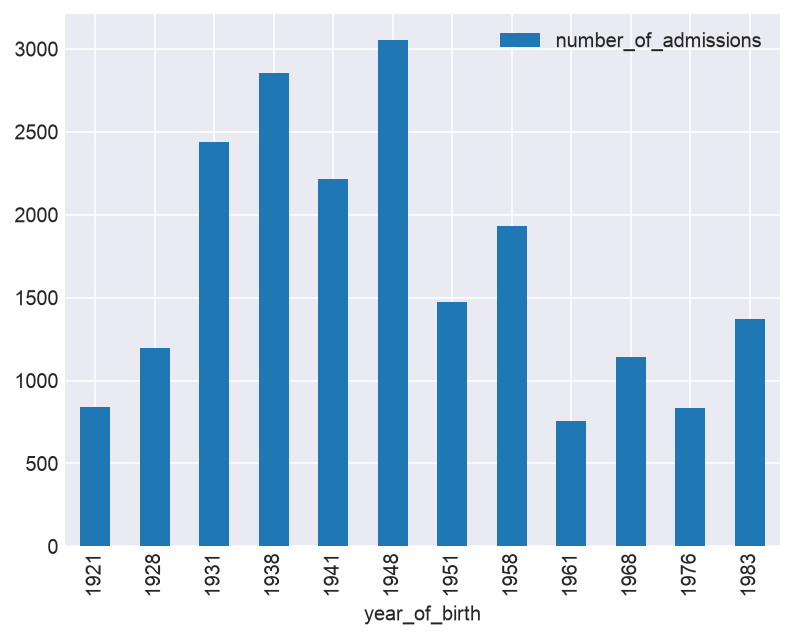

In [12]:
# modifies the pyplot back-end of Pandas to increase render resolution
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams["figure.dpi"] = 144

year_of_birth.plot(kind='bar', x='year_of_birth')

# Visit_occurrence
This table stores information about the ICU admissions. Patients (`person`) can have multiple visit_occurrence records.

This table is very similar to the legacy `admissions` table.

In [13]:
visit_occurrence = client.query(
    '''
    SELECT *
    FROM visit_occurrence
    '''
    , job_config=job_config).to_dataframe()

visit_occurrence.head(10)

,visit_occurrence_id,person_id,visit_concept_id,visit_start_date,visit_start_datetime,visit_end_date,visit_end_datetime,visit_type_concept_id,provider_id,care_site_id,visit_source_value,visit_source_concept_id,admitted_from_concept_id,admitted_from_source_value,discharged_to_concept_id,discharged_to_source_value,preceding_visit_occurrence_id
0,16628,14352,32037,2007-09-19,2007-09-19 06:53:00+00:00,2007-11-07,2007-11-07 09:59:00+00:00,32827,1,1,IC,<NA>,<NA>,NaN,581383,15,16627
1,3822,3320,32037,2009-12-10,2009-12-10 17:04:00+00:00,2009-12-14,2009-12-14 23:10:00+00:00,32827,23,2,MC,<NA>,8717,Verpleegafdeling zelfde ziekenhuis,9201,40,3821
2,6912,5965,32037,2013-06-16,2013-06-16 05:59:00+00:00,2013-06-16,2013-06-16 23:37:00+00:00,32827,25,2,MC,<NA>,8717,Verpleegafdeling zelfde ziekenhuis,9201,41,6911
3,10239,8828,32037,2013-06-14,2013-06-14 14:50:00+00:00,2013-06-16,2013-06-16 13:22:00+00:00,32827,25,1,IC,<NA>,8717,Verpleegafdeling zelfde ziekenhuis,9201,41,10238
4,2528,2199,32037,2013-06-15,2013-06-15 18:04:00+00:00,2013-06-16,2013-06-16 12:41:00+00:00,32827,12,2,MC,<NA>,<NA>,NaN,9201,46,2527
5,16346,14112,32037,2009-03-30,2009-03-30 15:24:00+00:00,2009-04-03,2009-04-03 17:25:00+00:00,32827,23,1,IC&MC,<NA>,<NA>,NaN,9201,47,16345
6,16075,13873,32037,2013-06-02,2013-06-02 02:23:00+00:00,2013-06-17,2013-06-17 14:37:00+00:00,32827,14,1,IC,<NA>,<NA>,NaN,581383,15,16074
7,4781,4160,32037,2013-05-13,2013-05-13 02:04:00+00:00,2013-06-17,2013-06-17 01:48:00+00:00,32827,14,1,IC&MC,<NA>,<NA>,NaN,9201,47,4780
8,19531,16851,32037,2014-02-28,2014-02-28 06:41:00+00:00,2014-02-28,2014-02-28 15:34:00+00:00,32827,2,1,IC,<NA>,8717,Verpleegafdeling zelfde ziekenhuis,<NA>,Overleden,19530
9,16838,14537,32037,2015-07-20,2015-07-20 13:57:00+00:00,2015-07-25,2015-07-25 11:05:00+00:00,32827,6,2,MC,<NA>,<NA>,NaN,9201,25,16837


In [14]:
provider = client.query(
    '''
    SELECT *
    FROM provider
    '''
    , job_config=job_config).to_dataframe()

provider.head(10)

,provider_id,provider_name,npi,dea,specialty_concept_id,care_site_id,year_of_birth,gender_concept_id,provider_source_value,specialty_source_value,specialty_source_concept_id,gender_source_value,gender_source_concept_id
0,60,NaN,NaN,NaN,38003716,<NA>,<NA>,<NA>,Uitzendkrachten,Uitzendkrachten,<NA>,NaN,<NA>
1,40,NaN,NaN,NaN,38003719,<NA>,<NA>,<NA>,ICV_IC-Verpleegkundig,ICV_IC-Verpleegkundig,<NA>,NaN,<NA>
2,41,NaN,NaN,NaN,38003719,<NA>,<NA>,<NA>,ICV_MC-Verpleegkundig,ICV_MC-Verpleegkundig,<NA>,NaN,<NA>
3,34,NaN,NaN,NaN,38004490,<NA>,<NA>,<NA>,FYS_Fysiotherapie,FYS_Fysiotherapie,<NA>,NaN,<NA>
4,22,NaN,NaN,NaN,38004491,<NA>,<NA>,<NA>,Reumatologie,Reumatologie,<NA>,NaN,<NA>
5,25,NaN,NaN,NaN,38004496,<NA>,<NA>,<NA>,Vaatchirurgie,Vaatchirurgie,<NA>,NaN,<NA>
6,1,NaN,NaN,NaN,38004497,<NA>,<NA>,<NA>,Cardiochirurgie,Cardiochirurgie,<NA>,NaN,<NA>
7,30,NaN,NaN,NaN,38004497,<NA>,<NA>,<NA>,CCH_Cardiochirurgie,CCH_Cardiochirurgie,<NA>,NaN,<NA>
8,8,NaN,NaN,NaN,38004500,<NA>,<NA>,<NA>,Intensive Care Volwassenen,Intensive Care Volwassenen,<NA>,NaN,<NA>
9,42,NaN,NaN,NaN,38004500,<NA>,<NA>,<NA>,ICV_Medisch,ICV_Medisch,<NA>,NaN,<NA>


## Concept

In [15]:
concept = client.query(
    '''
    SELECT *
    FROM concept
    WHERE concept_id = 38004497
    '''
    , job_config=job_config).to_dataframe()

concept.head(10)

,concept_id,concept_name,domain_id,vocabulary_id,concept_class_id,standard_concept,concept_code,valid_start_date,valid_end_date,invalid_reason
0,38004497,Cardiac Surgery,Provider,Medicare Specialty,Physician Specialty,S,78,1970-01-01,2099-12-31,NaN


# Query AmsterdamUMCdb through pandas-gbq

The third option is to query the dataset using the Pandas `pandas-gbq` library. Especially when you are already familiar with the `pandas.read_sql` function, it's relatively straightforward to modify your existing code to be compatible with BigQuery. For more information, see [Pandas GBQ Documentation](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.read_gbq.html).


**Note**: The `use_bqstorage_api=True` statement enables the Google Cloud BigQuery Storage API that improves the performance of copying data from BiqQuery to pandas DataFrames in the Colab environment (~around 16 times). While the usage of the Storage Read API is being charged separately, Google currently offers a free tier of 300 TB per month. However, you may choose to remove the option from the command.

## Set the default query job configuration for pandas-gbq

In [16]:
import pandas as pd

config_gbq = {'query':
          {'defaultDataset': {
              "datasetId": DATASET_ID,
              "projectId": DATASET_PROJECT_ID
              },
           'Location': LOCATION}
           }

## Retrieve the medical specialty associated with each admission

Downloading: 100%|██████████|


<Axes: xlabel='specialty'>

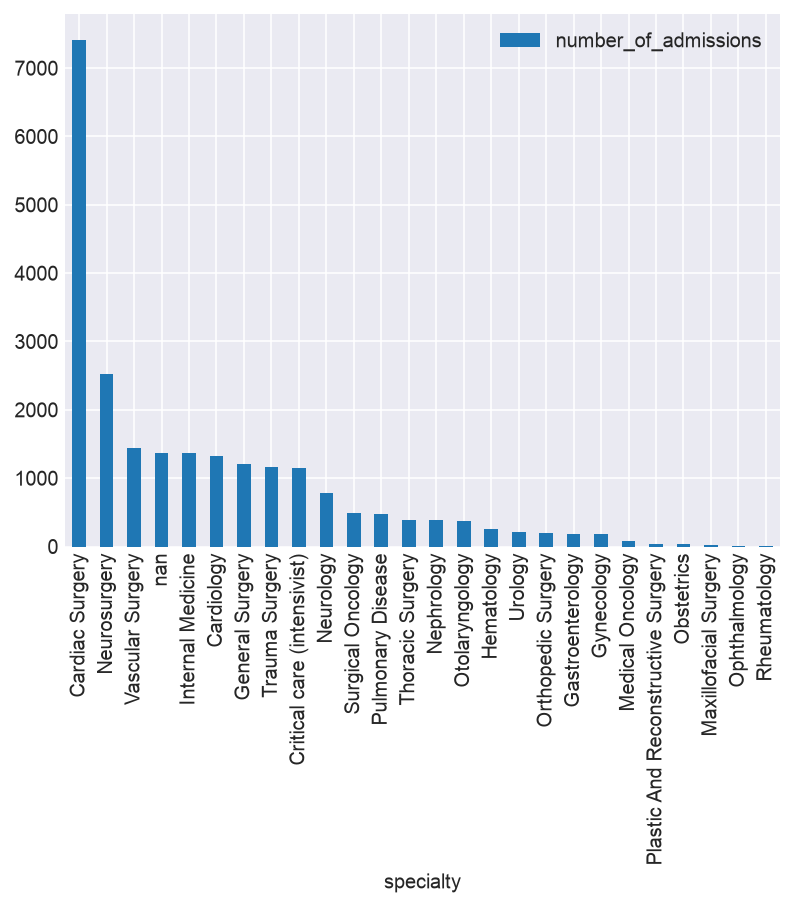

In [17]:
import pandas_gbq

specialties = pandas_gbq.read_gbq(
    '''
    SELECT concept_name AS specialty, COUNT(*) AS number_of_admissions
    FROM visit_occurrence v
    LEFT JOIN provider p ON p.provider_id = v.provider_id
    LEFT JOIN concept c ON c.concept_id = p.specialty_concept_id

    GROUP BY specialty
    ORDER BY number_of_admissions DESC
    '''
    , project_id=PROJECT_ID
    , location=LOCATION
    , configuration=config_gbq
    , use_bqstorage_api=True)

specialties.plot(kind='bar', x='specialty')

# Getting the data you need
The `amsterdamumcdb` package provides the `get_dictionary()` function that returns a DataFrame containing all codes and (categorical) values ('concepts') of AmsterdamUMCdb. As part of the transformation to the OMOP Common Data Model, most concepts have been mapped to a Standard Concept in the [OMOP Standardized Vocabularies](https://ohdsi.github.io/TheBookOfOhdsi/StandardizedVocabularies.html).

The Standardized Vocabularies are a common respository for commonly used vocabularies such as [LOINC](https://decor.nictiz.nl/art-decor/loinc), [SNOMED CT](https://decor.nictiz.nl/art-decor/snomed-ct), [RxNorm](https://mor.nlm.nih.gov/RxNav/) and [ATC](https://www.whocc.no/atc_ddd_index/). The OMOP Standardized Vocabularies are available at [ATHENA](https://athena.ohdsi.org/search-terms/start).

**Note for users of the legacy (non-OMOP) versions (≤ 1.0.2) of AmsterdamUMCdb**

The original `itemid` is stored as `source_code` and `item` as `source_code_description` in the dictionary. To allow mapping of categorical values from the legacy `listitems` table to standard concepts, the `source_code` was generated using the format `{itemid}-{valueid}`. In addition, the `source_code` from the legacy `drugitems` was generated using the `{itemid}-{ordercategoryid}` format.

## Install the AmsterdamUMCdb package

In [18]:
# get the amsterdamumcdb package from PyPI repository for use in Colab
%pip install sqlalchemy psycopg2-binary
!pip install amsterdamumcdb
import amsterdamumcdb as adb

Note: you may need to restart the kernel to use updated packages.


## Load the AmsterdamUMCdb dictionary.
Use the **Filter** button to quickly browse through the dictionary.

In [19]:
dictionary = adb.get_dictionary()
dictionary = dictionary.convert_dtypes()
dictionary.head(10)

,concept_id,concept_name,domain_id,concept_class_id,vocabulary_id,concept_code,source_vocabulary_id,source_code,source_code_description,value_of_concept_id,value_of_source_code,source_frequency,source_frequency_validated,mapping_status,equivalence
0,8532,FEMALE,Gender,Gender,Gender,F,AUMC Gender,Vrouw,Vrouw,<NA>,<NA>,7875,7875,APPROVED,EQUAL
1,8507,MALE,Gender,Gender,Gender,M,AUMC Gender,Man,Man,<NA>,<NA>,14735,14735,APPROVED,EQUAL
2,581476,Home Visit,Visit,Visit,Visit,OMOP4822459,AUMC Origin,Huis,Huis,<NA>,<NA>,85,85,APPROVED,EQUAL
3,581383,Inpatient Cardiac Care Facility,Visit,Visit,CMS Place of Service,OMOP4822038,AUMC Origin,CCU/IC zelfde ziekenhuis,CCU/IC zelfde ziekenhuis,<NA>,<NA>,296,296,APPROVED,EQUAL
4,8870,Emergency Room - Hospital,Visit,Visit,CMS Place of Service,23,AUMC Origin,Eerste Hulp afdeling zelfde ziekenhuis,Eerste Hulp afdeling zelfde ziekenhuis,<NA>,<NA>,2661,2661,APPROVED,EQUAL
5,581379,Inpatient Critical Care Facility,Visit,Visit,CMS Place of Service,OMOP4822042,AUMC Origin,Recovery ander ziekenhuis,Recovery ander ziekenhuis,<NA>,<NA>,6,6,APPROVED,EQUAL
6,8870,Emergency Room - Hospital,Visit,Visit,CMS Place of Service,23,AUMC Origin,Eerste Hulp afdeling ander ziekenhuis,Eerste Hulp afdeling ander ziekenhuis,<NA>,<NA>,132,132,APPROVED,EQUAL
7,8717,Inpatient Hospital,Visit,Visit,CMS Place of Service,21,AUMC Origin,Operatiekamer vanaf verpleegafdeling zelfde zi...,Operatiekamer vanaf verpleegafdeling zelfde zi...,<NA>,<NA>,5,5,APPROVED,EQUAL
8,581379,Inpatient Critical Care Facility,Visit,Visit,CMS Place of Service,OMOP4822042,AUMC Origin,Special/Medium care ander ziekenhuis,Special/Medium care ander ziekenhuis,<NA>,<NA>,19,19,APPROVED,EQUAL
9,8870,Emergency Room - Hospital,Visit,Visit,CMS Place of Service,23,AUMC Origin,Operatiekamer vanaf Eerste Hulp afdeling zelfd...,Operatiekamer vanaf Eerste Hulp afdeling zelfd...,<NA>,<NA>,2,2,APPROVED,EQUAL


# Selecting relevant features


## Example: Lactate
Lactate, a laboratory measurement, can be found in the `measurement` table.

Since this is the largest table of AmsterdamUMCdb (188 GiB), it is highly recommended to correctly filter the query on:
- `provider_id` and
  - `measurement_concept_id` or
  - `measurement_concept_id`/`person_id` or
  - `measurement_concept_id`/`person_id`/`measurement_start_time`

### Get all lactate itemids

In [20]:
lactate_ids = dictionary[dictionary['concept_name'].str.contains(r'lactate', case=False)]
lactate_ids.head(10)

,concept_id,concept_name,domain_id,concept_class_id,vocabulary_id,concept_code,source_vocabulary_id,source_code,source_code_description,value_of_concept_id,value_of_source_code,source_frequency,source_frequency_validated,mapping_status,equivalence
1263,40709262,500 ML Calcium Chloride 0.268 MG/ML / Lactate ...,Drug,Marketed Product,RxNorm Extension,OMOP4747901,AUMC Drug,7316-55,Ri-Lac (Ringers lactaat),<NA>,<NA>,36561,36561,APPROVED,EQUAL
5961,36878802,sodium dl-lactate,Drug,Ingredient,RxNorm Extension,OMOP1005620,AUMC Obs Value,7672-1,BH504,1988427,7672,1403,1403,APPROVED,INEXACT
5964,36878802,sodium dl-lactate,Drug,Ingredient,RxNorm Extension,OMOP1005620,AUMC Obs Value,7672-6,BH504/HF32bic,1988427,7672,80,80,APPROVED,INEXACT
7121,3016436,Lactate dehydrogenase [Enzymatic activity/volu...,Measurement,Lab Test,LOINC,2532-0,AUMC Laboratory,12023,LD (bloed),<NA>,<NA>,66406,66406,APPROVED,EQUAL
7125,3008338,Lactate dehydrogenase [Enzymatic activity/volu...,Measurement,Lab Test,LOINC,2529-6,AUMC Laboratory,12024,LD (overig),<NA>,<NA>,406,406,APPROVED,EQUAL
7575,3008581,Lactate dehydrogenase [Enzymatic activity/volu...,Measurement,Lab Test,LOINC,2531-2,AUMC Laboratory,18436,LD ascitesvocht (ascitesvocht),<NA>,<NA>,54,54,APPROVED,EQUAL
7583,3015054,Lactate dehydrogenase [Enzymatic activity/volu...,Measurement,Lab Test,LOINC,2530-4,AUMC Laboratory,18437,LD pleuravocht (pleurapunct.),<NA>,<NA>,226,226,APPROVED,EQUAL
7688,3047181,Lactate [Moles/volume] in Blood,Measurement,Lab Test,LOINC,32693-4,AUMC Laboratory,10053,Lactaat (bloed),<NA>,<NA>,182155,182155,APPROVED,EQUAL
8019,3014111,Lactate [Moles/volume] in Serum or Plasma,Measurement,Lab Test,LOINC,2524-7,AUMC Laboratory,6837,Laktaat,<NA>,<NA>,1476,1476,APPROVED,EQUAL
8020,3016436,Lactate dehydrogenase [Enzymatic activity/volu...,Measurement,Lab Test,LOINC,2532-0,AUMC Laboratory,6838,LDH,<NA>,<NA>,1522,1522,APPROVED,EQUAL


## Get lactate values for all patients

In [21]:
lactate = pandas_gbq.read_gbq(
    '''
    SELECT
      person_id,
      visit_occurrence_id,
      measurement_concept_id,
      measurement_datetime,
      measurement_type_concept_id,
      value_as_number,
      unit_concept_id,
      provider_id
    FROM measurement
    WHERE
      NOT provider_id IS NULL -- ignore unvalidated device data
      AND measurement_concept_id IN (
      3047181,  -- Lactate [Moles/volume] in Blood
      3014111,  -- Lactate [Moles/volume] in Serum
      3047181   -- Lactate [Moles/volume] in Blood
    )
    '''
    , configuration=config_gbq, use_bqstorage_api=True)

#show number of records in the dataframe
print(f'Number of lactate values: {len(lactate)}')

#show first 1000 items
lactate.convert_dtypes().head(10)

Downloading: 100%|██████████|
Number of lactate values: 184548


,person_id,visit_occurrence_id,measurement_concept_id,measurement_datetime,measurement_type_concept_id,value_as_number,unit_concept_id,provider_id
0,7010,8132,3047181,2006-06-13 20:34:00+00:00,32856,2.00000000000000000000000000000000000000,8753,58
1,7010,8132,3047181,2006-06-13 15:38:00+00:00,32817,1.90000000000000000000000000000000000000,8753,40
2,7010,8132,3047181,2006-06-13 11:34:00+00:00,32817,1.90000000000000000000000000000000000000,8753,40
3,7010,8132,3047181,2006-06-13 23:34:00+00:00,32817,2.30000000000000000000000000000000000000,8753,40
4,5885,6820,3047181,2008-07-20 19:20:00+00:00,32817,0.80000001000000000000000000000000000000,8753,40
5,12577,14580,3047181,2009-04-02 15:24:00+00:00,32856,1.30000000000000000000000000000000000000,8753,58
6,12577,14580,3047181,2009-04-02 17:34:00+00:00,32856,1.30000000000000000000000000000000000000,8753,58
7,14112,16346,3047181,2009-04-02 15:31:00+00:00,32856,0.80000001000000000000000000000000000000,8753,58
8,617,707,3047181,2010-08-27 12:40:00+00:00,32856,4.00000000000000000000000000000000000000,8753,58
9,13559,15714,3047181,2013-06-16 22:48:00+00:00,32856,1.20000000000000000000000000000000000000,8753,58


### Plot lactate values using default pandas histogram function

<Axes: >

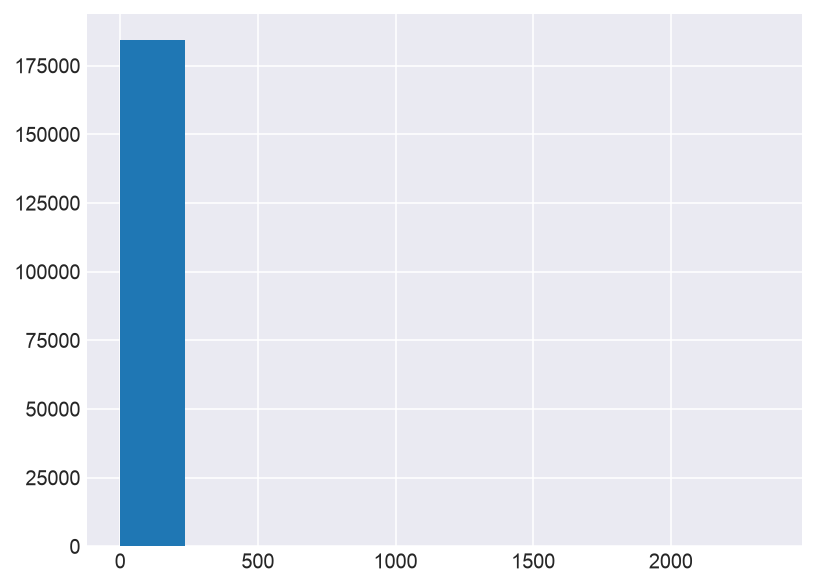

In [22]:
lactate['value'] = lactate['value_as_number'].astype('float')
lactate['value'].hist()

### Plot lactate values using outlier aware histogram from AmsterdamUMCdb library

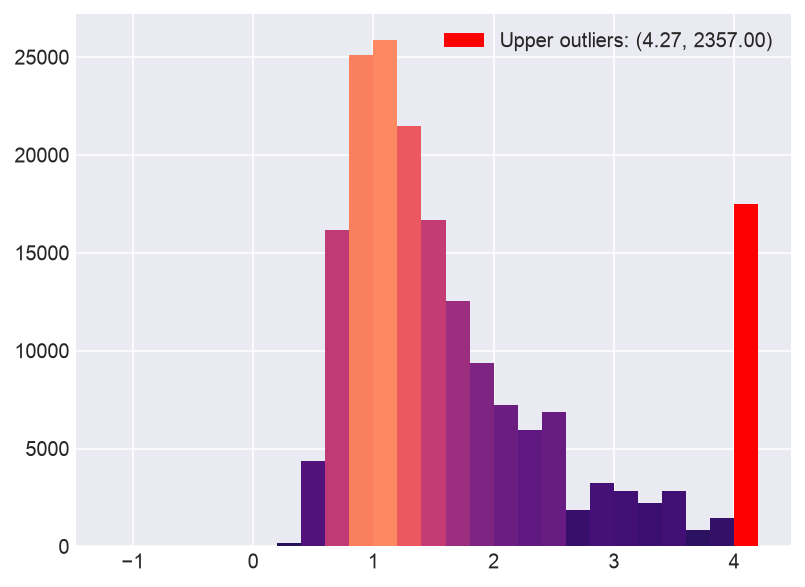

In [24]:
import matplotlib
import matplotlib.pyplot as plt

# was removed in matplotlib 3.9
if not hasattr(plt.cm, 'get_cmap'):
    plt.cm.get_cmap = matplotlib.colormaps.get_cmap

adb.outliers_histogram(data=lactate['value']).show()

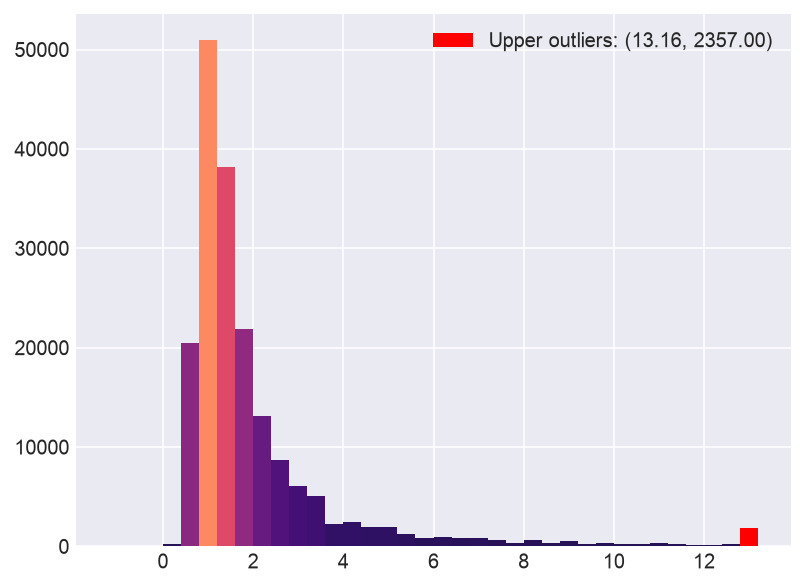

In [25]:
adb.outliers_histogram(data=lactate['value'], z_threshold=16).show()

In [27]:
lactate[lactate['value'] > 15].sort_values('value', ascending=False).head(10)

,person_id,visit_occurrence_id,measurement_concept_id,measurement_datetime,measurement_type_concept_id,value_as_number,unit_concept_id,provider_id,value
180000,5249,6056,3047181,2006-03-30 00:34:00+00:00,32817,2357.00000000000000000000000000000000000000,8753,40,2357.000000
80819,5951,6893,3047181,2005-12-31 19:41:00+00:00,32817,254.00000000000000000000000000000000000000,8753,40,254.000000
161183,6947,8060,3047181,2006-01-21 10:38:00+00:00,32817,134.00000000000000000000000000000000000000,8753,40,134.000000
130194,6412,7447,3047181,2006-01-06 16:34:00+00:00,32817,104.00000000000000000000000000000000000000,8753,40,104.000000
106684,2086,2397,3014111,2006-01-06 04:15:00+00:00,32817,81.00000000000000000000000000000000000000,8753,42,81.000000
106683,13934,16147,3014111,2006-04-06 00:58:00+00:00,32817,54.00000000000000000000000000000000000000,8753,40,54.000000
7155,2071,2377,3047181,2012-12-31 21:37:00+00:00,32856,41.00000000000000000000000000000000000000,8753,58,41.000000
130378,6608,7669,3047181,2006-01-06 04:47:00+00:00,32856,38.09999800000000000000000000000000000000,8753,58,38.099998
129826,6608,7669,3047181,2006-01-06 02:36:00+00:00,32856,38.00000000000000000000000000000000000000,8753,58,38.000000
126041,6608,7669,3047181,2006-01-05 01:25:00+00:00,32856,37.90000200000000000000000000000000000000,8753,58,37.900002


This table demonstrates that the top 6 highest values are most likely data entry errors. They were also manually documented in the EHR (`measurement_type_concept_id` = [32817](https://athena.ohdsi.org/search-terms/terms?standardConcept=Standard&invalidReason=Valid&domain=Type+Concept&page=1&pageSize=15&query=32817)), instead of being filed by the Laboratory system (`measurement_type_concept_id` = [32856](https://athena.ohdsi.org/search-terms/terms?standardConcept=Standard&invalidReason=Valid&domain=Type+Concept&page=1&pageSize=15&query=32856&boosts)).

## Example: Acute kidney injury: creatinine
Creatinine, a laboratory measurement that reflects kidney function, can also be found in the `measurement` table.

### Get all creatinine itemids

In [28]:
creatinine_ids = dictionary[dictionary['concept_name'].str.contains(r'creatinine', case=False)]
creatinine_ids

,concept_id,concept_name,domain_id,concept_class_id,vocabulary_id,concept_code,source_vocabulary_id,source_code,source_code_description,value_of_concept_id,value_of_source_code,source_frequency,source_frequency_validated,mapping_status,equivalence
7369,3009508,Creatinine [Moles/volume] in Urine,Measurement,Lab Test,LOINC,14683-7,AUMC Laboratory,10279,Kreatinine (urine),<NA>,<NA>,3340,3340,APPROVED,EQUAL
7410,3005770,Creatinine renal clearance in 24 hour Urine an...,Measurement,Lab Test,LOINC,2164-2,AUMC Laboratory,11900,Kreat.klaring (urine),<NA>,<NA>,91,91,APPROVED,EQUAL
7415,3005770,Creatinine renal clearance in 24 hour Urine an...,Measurement,Lab Test,LOINC,2164-2,AUMC Laboratory,11901,KREAT.KLAR (verz. urine),<NA>,<NA>,167,167,APPROVED,EQUAL
7710,3020564,Creatinine [Moles/volume] in Serum or Plasma,Measurement,Lab Test,LOINC,14682-9,AUMC Laboratory,9941,Kreatinine (bloed),<NA>,<NA>,196186,196186,APPROVED,EQUAL
7756,3020564,Creatinine [Moles/volume] in Serum or Plasma,Measurement,Lab Test,LOINC,14682-9,AUMC Laboratory,14216,KREAT enzym. (bloed),<NA>,<NA>,33,33,APPROVED,EQUAL
7780,3026726,Creatinine [Moles/volume] in Specimen,Measurement,Lab Test,LOINC,22726-4,AUMC Laboratory,14441,Kreatinine (overig),<NA>,<NA>,197,197,APPROVED,EQUAL
7788,46236952,Glomerular filtration rate/1.73 sq M.predicted...,Measurement,Lab Test,LOINC,77147-7,AUMC Laboratory,14442,eGFR(MDRD) (bloed),<NA>,<NA>,128371,128371,APPROVED,EQUAL
8016,3020564,Creatinine [Moles/volume] in Serum or Plasma,Measurement,Lab Test,LOINC,14682-9,AUMC Laboratory,6836,Kreatinine,<NA>,<NA>,6481,6481,APPROVED,EQUAL


### Get creatinine values for all patients

In [30]:
creatinine = pandas_gbq.read_gbq(
    '''
    SELECT
      person_id,
      visit_occurrence_id,
      measurement_concept_id,
      measurement_datetime,
      measurement_type_concept_id,
      value_as_number,
      unit_concept_id,
      provider_id
    FROM measurement
    WHERE
      NOT provider_id IS NULL -- ignore unvalidated device data
      AND measurement_concept_id IN (
        3020564 -- Creatinine [Moles/volume] in Serum or Plasma
    )
    '''
    , configuration=config_gbq, use_bqstorage_api=True)

#show number of records in the dataframe
print(f'Number of creatinine values: {len(creatinine)}')

#show first 1000 items
creatinine.head(10)

Downloading: 100%|██████████|
Number of creatinine values: 202700


,person_id,visit_occurrence_id,measurement_concept_id,measurement_datetime,measurement_type_concept_id,value_as_number,unit_concept_id,provider_id
0,570,656,3020564,2006-01-01 05:00:00+00:00,32817,123.00000000000000000000000000000000000000,8749,27
1,2401,2780,3020564,2013-01-14 07:42:00+00:00,32817,1.00000000000000000000000000000000000000,8749,27
2,2075,2382,3020564,2006-03-09 06:43:00+00:00,32817,51.00000000000000000000000000000000000000,8749,37
3,633,723,3020564,2006-01-12 17:36:00+00:00,32817,72.00000000000000000000000000000000000000,8749,37
4,2011,2307,3020564,2006-01-01 05:49:00+00:00,32817,102.00000000000000000000000000000000000000,8749,40
5,12,12,3020564,2006-01-04 02:15:00+00:00,32817,60.00000000000000000000000000000000000000,8749,40
6,901,1036,3020564,2006-01-01 01:53:00+00:00,32817,101.00000000000000000000000000000000000000,8749,40
7,1121,1292,3020564,2006-01-01 03:13:00+00:00,32817,91.00000000000000000000000000000000000000,8749,40
8,458,525,3020564,2006-01-01 04:22:00+00:00,32817,144.00000000000000000000000000000000000000,8749,40
9,1125,1296,3020564,2006-01-01 02:38:00+00:00,32817,96.00000000000000000000000000000000000000,8749,40


### Plot creatinine values using default pandas histogram function

<Axes: >

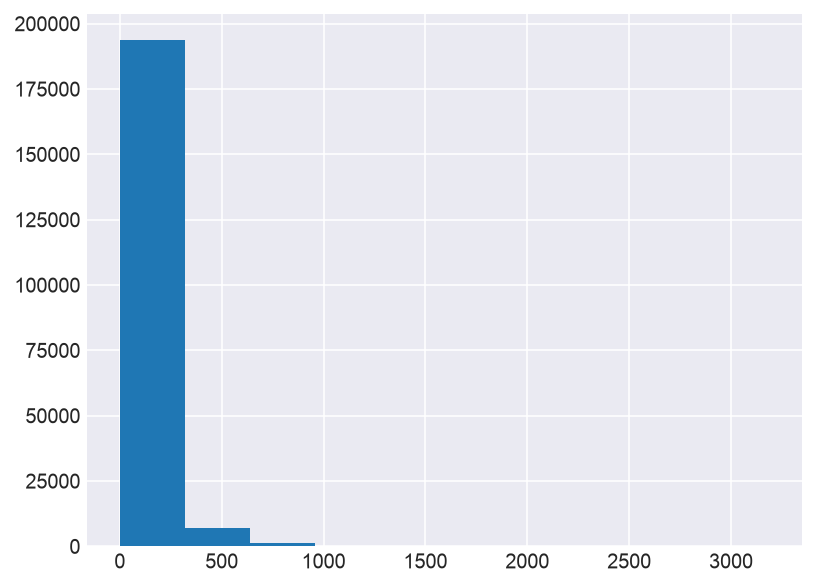

In [31]:
creatinine['value'] = creatinine['value_as_number'].astype('float')
creatinine['value'].hist()

### Plot creatinine values using outlier aware histogram from AmsterdamUMCdb library

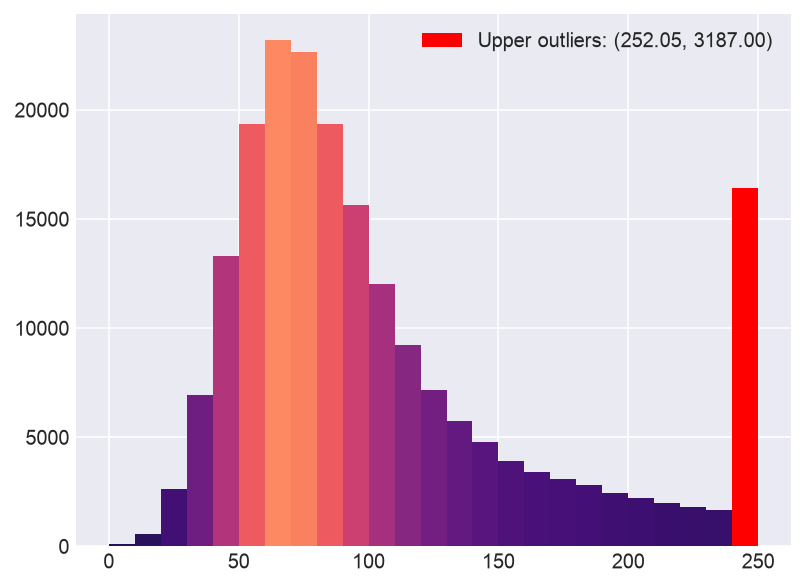

In [32]:
adb.outliers_histogram(data=creatinine['value']).show()

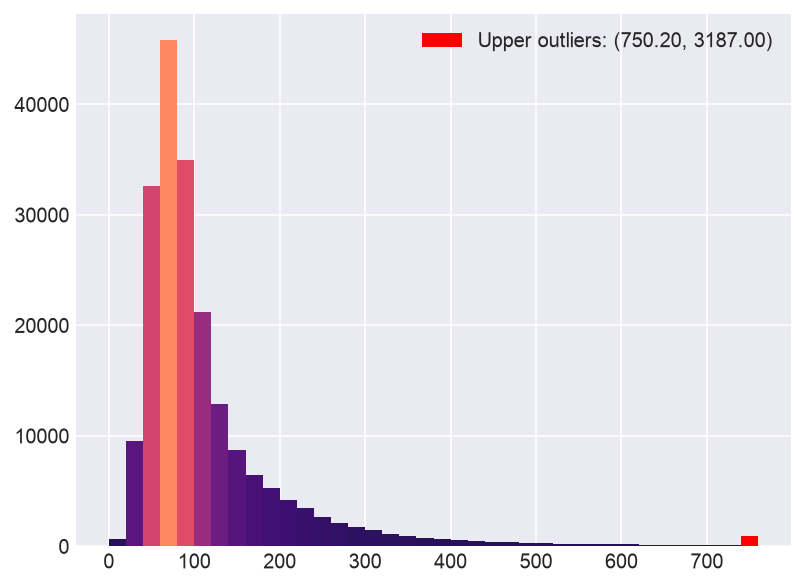

In [33]:
adb.outliers_histogram(data=creatinine['value'], z_threshold=16).show()

In [35]:
creatinine[creatinine['value'] > 500].sort_values('value', ascending=False).head(10)

,person_id,visit_occurrence_id,measurement_concept_id,measurement_datetime,measurement_type_concept_id,value_as_number,unit_concept_id,provider_id,value
125,1375,1583,3020564,2006-01-07 01:45:00+00:00,32817,3187.00000000000000000000000000000000000000,8749,40,3187.0
192801,7204,8361,3020564,2012-12-31 17:39:00+00:00,32856,2326.00000000000000000000000000000000000000,8749,58,2326.0
192800,6580,7637,3020564,2013-01-01 00:01:00+00:00,32817,2157.00000000000000000000000000000000000000,8749,43,2157.0
192799,7913,9187,3020564,2012-12-31 22:54:00+00:00,32856,2072.00000000000000000000000000000000000000,8749,58,2072.0
192798,10174,11786,3020564,2012-12-31 21:03:00+00:00,32856,2042.00000000000000000000000000000000000000,8749,58,2042.0
192797,14781,17116,3020564,2012-12-31 20:31:00+00:00,32856,1999.00000000000000000000000000000000000000,8749,58,1999.0
194769,7913,9188,3020564,2013-08-04 12:47:00+00:00,32856,1990.00000000000000000000000000000000000000,8749,58,1990.0
192795,10174,11786,3020564,2013-01-01 00:54:00+00:00,32856,1980.00000000000000000000000000000000000000,8749,58,1980.0
192796,16362,18974,3020564,2012-12-31 18:51:00+00:00,32856,1980.00000000000000000000000000000000000000,8749,58,1980.0
192794,7204,8361,3020564,2013-01-01 07:02:00+00:00,32856,1970.00000000000000000000000000000000000000,8749,58,1970.0


In [38]:
creat_patient = pandas_gbq.read_gbq(
    '''
    SELECT
      person_id,
      visit_occurrence_id,
      measurement_concept_id,
      measurement_datetime,
      measurement_type_concept_id,
      CAST(value_as_number AS FLOAT64) as value_as_number,
      unit_concept_id,
      provider_id
    FROM measurement
    WHERE
      NOT provider_id IS NULL -- ignore unvalidated device data
      AND measurement_concept_id IN (
        3020564 -- Creatinine [Moles/volume] in Serum or Plasma
      )
      AND visit_occurrence_id = 1583
    ORDER BY measurement_datetime
    '''
    , configuration=config_gbq, use_bqstorage_api=True)
creat_patient.head(1000)

Downloading: 100%|██████████|


,person_id,visit_occurrence_id,measurement_concept_id,measurement_datetime,measurement_type_concept_id,value_as_number,unit_concept_id,provider_id
0,1375,1583,3020564,2006-01-01 03:45:00+00:00,32817,207.0,8749,42
1,1375,1583,3020564,2006-01-01 06:45:00+00:00,32817,226.0,8749,40
2,1375,1583,3020564,2006-01-01 10:45:00+00:00,32817,249.0,8749,40
3,1375,1583,3020564,2006-01-01 19:45:00+00:00,32817,291.0,8749,42
4,1375,1583,3020564,2006-01-02 01:45:00+00:00,32817,335.0,8749,42
5,1375,1583,3020564,2006-01-02 07:45:00+00:00,32817,345.0,8749,42
6,1375,1583,3020564,2006-01-02 13:45:00+00:00,32817,313.0,8749,44
7,1375,1583,3020564,2006-01-02 19:45:00+00:00,32817,291.0,8749,44
8,1375,1583,3020564,2006-01-03 01:45:00+00:00,32817,284.0,8749,40
9,1375,1583,3020564,2006-01-03 09:45:00+00:00,32817,279.0,8749,42


This table demonstrates that the highest value is most likely a data entry error: it was manually documented, instead of filed by the system (Dutch: 'Systeem')

# Tips and Tricks

# Getting related items
Assume you have determined that concept_id `40729817` (Hydrocortisone 100 MG Injectable Solution [Solu-Cortef]) is of interest, but would like to know if other steroids have been used on our unit.

In [40]:
ancestors = pandas_gbq.read_gbq(
    '''
    SELECT ancestor_concept_id, descendant_concept_id, min_levels_of_separation, concept_name, vocabulary_id, concept_class_id
    FROM concept_ancestor
    LEFT JOIN concept
      ON concept_ancestor.ancestor_concept_id = concept.concept_id
    WHERE descendant_concept_id = 40729817 -- Hydrocortisone 100 MG Injectable Solution [Solu-Cortef]
    ORDER BY min_levels_of_separation DESC
    '''
    , configuration=config_gbq, use_bqstorage_api=True)
ancestors

Downloading: 100%|██████████|


,ancestor_concept_id,descendant_concept_id,min_levels_of_separation,concept_name,vocabulary_id,concept_class_id
0,21602681,40729817,6,"SYSTEMIC HORMONAL PREPARATIONS, EXCL. SEX HORM...",ATC,ATC 1st
1,21602722,40729817,5,CORTICOSTEROIDS FOR SYSTEMIC USE,ATC,ATC 2nd
2,21602723,40729817,4,"CORTICOSTEROIDS FOR SYSTEMIC USE, PLAIN",ATC,ATC 3rd
3,21602728,40729817,3,Glucocorticoids,ATC,ATC 4th
4,36217210,40729817,3,Injectable Product,RxNorm,Dose Form Group
5,975125,40729817,2,hydrocortisone,RxNorm,Ingredient
6,21602737,40729817,2,hydrocortisone; systemic,ATC,ATC 5th
7,36218389,40729817,2,hydrocortisone Injectable Product,RxNorm,Clinical Dose Group
8,35604742,40729817,1,hydrocortisone 100 MG [Solu-Cortef],RxNorm,Branded Drug Comp
9,35604741,40729817,1,hydrocortisone 100 MG,RxNorm,Clinical Drug Comp


In [42]:
descendants = pandas_gbq.read_gbq(
    '''
    SELECT descendant_concept_id
    FROM concept_ancestor
    WHERE ancestor_concept_id = 21602728 -- Glucocorticoids
    '''
    , configuration=config_gbq, use_bqstorage_api=True)

# filter dictionary on all descendants
dictionary[dictionary['concept_id'].isin(descendants['descendant_concept_id'])]

Downloading: 100%|██████████|


,concept_id,concept_name,domain_id,concept_class_id,vocabulary_id,concept_code,source_vocabulary_id,source_code,source_code_description,value_of_concept_id,value_of_source_code,source_frequency,source_frequency_validated,mapping_status,equivalence
757,40028601,dexamethasone Oral Tablet,Drug,Clinical Drug Form,RxNorm,371729,AUMC Drug,6995-71,Dexamethason,<NA>,<NA>,742,742,APPROVED,EQUAL
760,40028260,dexamethasone Injectable Solution,Drug,Clinical Drug Form,RxNorm,371725,AUMC Drug,6995-67,Dexamethason,<NA>,<NA>,7646,7646,APPROVED,EQUAL
904,40049700,hydrocortisone Oral Tablet,Drug,Clinical Drug Form,RxNorm,370649,AUMC Drug,7106-71,Hydrocortison (Solu Cortef),<NA>,<NA>,368,368,APPROVED,EQUAL
909,40729817,Hydrocortisone 100 MG Injectable Solution [Sol...,Drug,Branded Drug,RxNorm Extension,OMOP4727882,AUMC Drug,7106-67,Hydrocortison (Solu Cortef),<NA>,<NA>,63388,63388,APPROVED,EQUAL
1117,40073458,prednisolone Oral Tablet,Drug,Clinical Drug Form,RxNorm,373578,AUMC Drug,6922-71,Prednisolon (Prednison),<NA>,<NA>,2326,2326,APPROVED,EQUAL
1122,40073191,prednisolone Injectable Solution,Drug,Clinical Drug Form,RxNorm,373579,AUMC Drug,6922-67,Prednisolon (Prednison),<NA>,<NA>,6341,6341,APPROVED,EQUAL
1174,40060704,methylprednisolone Injectable Solution [Solu-M...,Drug,Branded Drug Form,RxNorm,362772,AUMC Drug,8132-65,Methylprednisolon (Solu-Medrol),<NA>,<NA>,10,10,APPROVED,EQUAL
1178,40060704,methylprednisolone Injectable Solution [Solu-M...,Drug,Branded Drug Form,RxNorm,362772,AUMC Drug,8132-67,Methylprednisolon (Solu-Medrol),<NA>,<NA>,1610,1610,APPROVED,EQUAL


In [43]:
corticosteroids = pandas_gbq.read_gbq(
    '''
    SELECT *
    FROM drug_exposure
    WHERE drug_concept_id IN (
      40028601,	-- dexamethasone Oral Tablet
      40028260,  -- dexamethasone Injectable Solution
      40049700,	-- hydrocortisone Oral Tablet
      40729817,  -- Hydrocortisone 100 MG Injectable Solution [Solu-Cortef]
      40073458,	-- prednisolone Oral Tablet
      40073191,	-- prednisolone Injectable Solution
      40060704,  -- methylprednisolone Injectable Solution [Solu-Medrol]
      40060704	-- methylprednisolone Injectable Solution [Solu-Medrol]
    )
    '''
    , configuration=config_gbq, use_bqstorage_api=True)

Downloading: 100%|██████████|


## Conclusion
This finalizes our tutorial on accessing AmsterdamUMCdb using BigQuery.

### What's next?
- Have a look at the AmsterdamUMCdb [wiki](https://github.com/AmsterdamUMC/AmsterdamUMCdb/wiki).
- More examples are available for the legacy tables. You can use the dictionary to translate the legacy `source_code`s to `concept_id`s. Future work will update this repository with examples for the OMOP Common Data Model.

Table | Wiki | Example code
:- | :--| -:
admissions|https://github.com/AmsterdamUMC/AmsterdamUMCdb/wiki/admissions | [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AmsterdamUMC/AmsterdamUMCdb/blob/master/tables/admissions.ipynb)
drugitems|https://github.com/AmsterdamUMC/AmsterdamUMCdb/wiki/drugitems|[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AmsterdamUMC/AmsterdamUMCdb/blob/master/tables/drugitems.ipynb)
freetextitems|https://github.com/AmsterdamUMC/AmsterdamUMCdb/wiki/freetextitems|[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AmsterdamUMC/AmsterdamUMCdb/blob/master/tables/freetextitems.ipynb)
listitems|https://github.com/AmsterdamUMC/AmsterdamUMCdb/wiki/lisitems|[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AmsterdamUMC/AmsterdamUMCdb/blob/master/tables/listitems.ipynb)
numericitems|https://github.com/AmsterdamUMC/AmsterdamUMCdb/wiki/numericitems|[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AmsterdamUMC/AmsterdamUMCdb/blob/master/tables/numericitems.ipynb)
procedureorderitems|https://github.com/AmsterdamUMC/AmsterdamUMCdb/wiki/procedureorderitems|[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AmsterdamUMC/AmsterdamUMCdb/blob/master/tables/procedureorderitems.ipynb)
processitems|https://github.com/AmsterdamUMC/AmsterdamUMCdb/wiki/processitems|[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AmsterdamUMC/AmsterdamUMCdb/blob/master/tables/processitems.ipynb)

- Examine the [concepts](https://github.com/AmsterdamUMC/AmsterdamUMCdb/tree/master/concepts) for definitions related to diagnoses, life support systems, including mechanical ventilation and renal replacement therapy, and ICU scoring systems.
- And remember: medical data science is always a joint effort of disciplines, so start a discussion with your colleagues or team members early on how to approach your clinical problem.
